# 09 — Attack Comparison

Compare **five watermark-removal attacks** against LLaDA-8B-Instruct: word deletion, WordNet synonym substitution, BERT context-aware substitution, Qwen paraphrasing, and Qwen back-translation.

**Local `.venv` only.** Uses saved JSONL outputs; **does not rerun any attack or watermark detector**. MPNet is loaded once to recompute/cache per-text semantic similarity for the two Qwen attacks. Run all cells in order from the repository's directory (or a subdirectory).

**Protocol:** ASR = fraction of *originally detected* texts no longer detected after attack. The classic attacks use ratio `0.5` in the headline comparison, but the full ratio sweep is shown. Semantic validity = MPNet cosine similarity ≥ `0.80` (heuristic, **not** a guarantee of meaning preservation).

## 1. Setup & load saved results

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from IPython.display import display


def find_root(start):
    for p in (start, *start.parents):
        if (p / "results" / "Cleaned Data" / "watermarked_600.jsonl").is_file():
            return p
    raise FileNotFoundError("Run this notebook inside the watermark project repository.")

ROOT = find_root(Path.cwd().resolve())
ATTACKS_DIR = ROOT / "results" / "attacks"
OUT_DIR = ATTACKS_DIR / "comparison"
OUT_DIR.mkdir(parents=True, exist_ok=True)


def read_jsonl(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required attack result not found: {path}")
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def wilson(k, n):
    ci = binomtest(k, n).proportion_ci(method="wilson")
    return (ci.low, ci.high)

baseline = read_jsonl(ATTACKS_DIR / "baseline_original.jsonl")
watermarked = read_jsonl(ROOT / "results" / "Cleaned Data" / "watermarked_600.jsonl")
assert len(baseline) == len(watermarked) == 600
assert all(b["idx"] == i and b["prompt"] == w["prompt"] for i, (b, w) in enumerate(zip(baseline, watermarked)))
eligible_ids = {b["idx"] for b in baseline if b["detected"]}
assert eligible_ids, "No originally detected texts"
print(f"Project: {ROOT}\nOriginally detected: {len(eligible_ids)}/600")

classic = {
    "Word deletion": ("word_deletion", "word_deletion"),
    "Synonym substitution": ("synonym_substitution", "synonym_substitution"),
    "BERT substitution": ("context_aware_substitution", "context_aware_substitution"),
}
qwen_paths = {
    "Qwen paraphrasing": ("paraphrasing", "paraphrasing_detection.jsonl", "paraphrased_texts_pairs.jsonl"),
    "Qwen back-translation": ("backtranslation", "backtranslation_detection.jsonl", "backtranslated_texts_pairs.jsonl"),
}


def validate_records(recs, label):
    assert len(recs) == len(baseline), f"{label}: wrong number of records"
    assert {r["idx"] for r in recs} == set(range(len(baseline))), f"{label}: duplicate/missing indexes"
    for r in recs:
        b, w = baseline[r["idx"]], watermarked[r["idx"]]
        assert bool(r["original_detected"]) == bool(b["detected"]), f"{label}: baseline mismatch"
        assert r["original"] == w["completion"], f"{label}: source text mismatch"
        assert isinstance(r["attacked"], str) and r["attacked"].strip(), f"{label}: empty attack"
        assert isinstance(r["detected"], bool), f"{label}: missing detection"
    return {r["idx"]: r for r in recs}

# All five ratios for the three classical attacks
classic_runs = {}
for label, (folder, stem) in classic.items():
    for ratio in [0.1, 0.2, 0.3, 0.4, 0.5]:
        # Notebook 04 additionally evaluates 0.0; omit the no-attack case from this chart.
        recs = read_jsonl(ATTACKS_DIR / folder / f"{stem}_r{ratio:.1f}.jsonl")
        classic_runs[(label, ratio)] = validate_records(recs, f"{label} r={ratio}")

qwen_runs, qwen_pairs = {}, {}
for label, (folder, detection_file, pairs_file) in qwen_paths.items():
    recs = read_jsonl(ATTACKS_DIR / folder / detection_file)
    qwen_runs[label] = validate_records(recs, label)
    pairs = read_jsonl(ATTACKS_DIR / folder / pairs_file)
    assert len(pairs) == 600 and {p["source_index"] for p in pairs} == set(range(600))
    qwen_pairs[label] = {p["source_index"]: p for p in pairs}
    for idx in range(600):
        p, r = qwen_pairs[label][idx], qwen_runs[label][idx]
        assert p["original"] == r["original"] and p["attacked"] == r["attacked"], f"{label}: attack/detection mismatch at {idx}"

print("All 5 attacks and 15 classic ratio files: validated.")

Project: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking
Originally detected: 583/600
All 5 attacks and 15 classic ratio files: validated.


## 2. Main comparison table

All methods use the same eligible set (originally watermarked responses detected by the baseline). Wilson intervals describe uncertainty in each observed ASR. They do **not** control for multiple comparisons.

In [2]:
def attack_stats(records):
    n = len(eligible_ids)
    successes = sum(not records[i]["detected"] for i in eligible_ids)
    low, high = wilson(successes, n)
    return {"Eligible": n, "Successes": successes, "ASR": successes / n,
            "CI low": low, "CI high": high}

rows = []
for name in classic:
    rows.append({"Attack": name, "Setting": "ratio = 0.5", **attack_stats(classic_runs[name, 0.5])})
for name, records in qwen_runs.items():
    rows.append({"Attack": name, "Setting": "Qwen", **attack_stats(records)})
main = pd.DataFrame(rows)
display(main.style.format({"ASR": "{:.2%}", "CI low": "{:.2%}", "CI high": "{:.2%}"}))
main.to_csv(OUT_DIR / "main_asr_comparison.csv", index=False)
print("Saved main_asr_comparison.csv")

,Attack,Setting,Eligible,Successes,ASR,CI low,CI high
0,Word deletion,ratio = 0.5,583,265,45.45%,41.46%,49.51%
1,Synonym substitution,ratio = 0.5,583,326,55.92%,51.86%,59.90%
2,BERT substitution,ratio = 0.5,583,130,22.30%,19.11%,25.85%
3,Qwen paraphrasing,Qwen,583,538,92.28%,89.83%,94.18%
4,Qwen back-translation,Qwen,583,371,63.64%,59.65%,67.44%


Saved main_asr_comparison.csv


## 3. Figure 1 — Attack strength (classical methods)

A ratio is the **requested** perturbation proportion, not necessarily the proportion actually changed (especially for BERT).

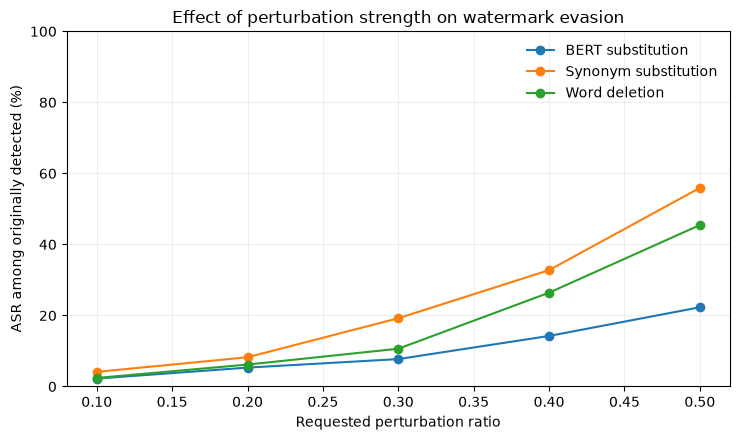

In [3]:
sweep = []
for (name, ratio), records in classic_runs.items():
    sweep.append({"Attack": name, "Ratio": ratio, **attack_stats(records)})
sweep = pd.DataFrame(sweep).sort_values(["Attack", "Ratio"])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for name, group in sweep.groupby("Attack", sort=False):
    ax.plot(group["Ratio"], group["ASR"] * 100, marker="o", label=name)
ax.set(xlabel="Requested perturbation ratio", ylabel="ASR among originally detected (%)",
       title="Effect of perturbation strength on watermark evasion", ylim=(0, 100))
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "figure_1_ratio_sweep.png", dpi=180)
plt.show()
sweep.to_csv(OUT_DIR / "classic_ratio_sweep.csv", index=False)

## 4. Semantic quality vs watermark evasion (Qwen)

Use the **same** MPNet model/threshold as notebooks 07 and 08. Embeddings are computed **only on the first run** or when attack texts change; results are cached as CSV under `results/attacks/comparison/`. The cache is verified using SHA-256 hashes of the original and attacked text. `trimmed` texts are retained in the main semantic-only comparison, consistent with notebooks 07/08. Failures/shortening remain a limitation.

/Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1122 14:38:26.601000 47283 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7885.89it/s]


Computing MPNet similarity on mps for: ['Qwen paraphrasing', 'Qwen back-translation']


Batches: 100%|██████████| 19/19 [00:20<00:00,  1.07s/it]


,Attack,Raw ASR,Filtered ASR,Joint success,Semantic validity (all),Median similarity,Valid eligible
0,Qwen paraphrasing,92.28%,91.92%,87.82%,95.50%,0.931,557
1,Qwen back-translation,63.64%,63.83%,60.55%,95.00%,0.959,553


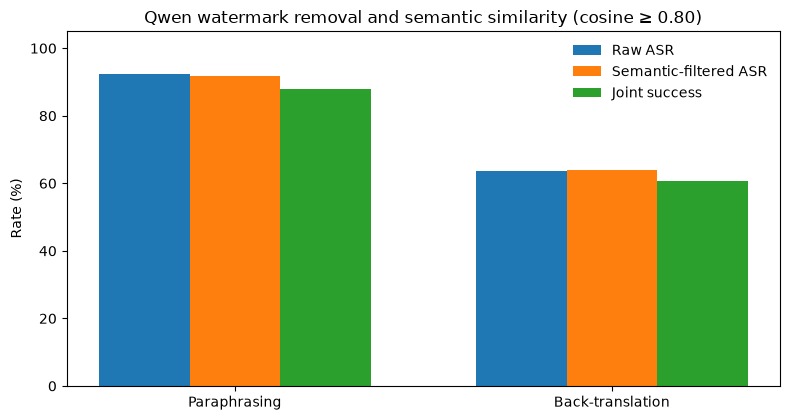

In [4]:
SIM_THRESHOLD = 0.80
SIM_MODEL = "sentence-transformers/all-mpnet-base-v2"


def digest(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def similarity_table(name):
    slug = "paraphrasing" if name == "Qwen paraphrasing" else "backtranslation"
    cache = OUT_DIR / f"{slug}_semantic_similarity.csv"
    pairs = qwen_pairs[name]
    fingerprints = [digest(pairs[i]["original"] + "\0" + pairs[i]["attacked"]) for i in range(600)]
    if cache.exists():
        df = pd.read_csv(cache)
        if (len(df) == 600 and list(df["source_index"]) == list(range(600))
                and list(df["fingerprint"]) == fingerprints
                and (df["model"] == SIM_MODEL).all()):
            print(f"Using validated similarity cache: {cache.name}")
            return df
    return None

sim_tables = {name: similarity_table(name) for name in qwen_runs}
missing = [name for name, table in sim_tables.items() if table is None]
if missing:
    import torch
    from sentence_transformers import SentenceTransformer
    device = ("cuda" if torch.cuda.is_available() else
              "mps" if torch.backends.mps.is_available() else "cpu")
    model = SentenceTransformer(SIM_MODEL, device=device)
    model.max_seq_length = 512
    print(f"Computing MPNet similarity on {device} for: {missing}")
    for name in missing:
        pairs = qwen_pairs[name]
        originals = [pairs[i]["original"] for i in range(600)]
        attacked = [pairs[i]["attacked"] for i in range(600)]
        a = model.encode(originals, batch_size=32, normalize_embeddings=True, show_progress_bar=True)
        b = model.encode(attacked, batch_size=32, normalize_embeddings=True, show_progress_bar=True)
        df = pd.DataFrame({"source_index": range(600),
                           "fingerprint": [digest(originals[i] + "\0" + attacked[i]) for i in range(600)],
                           "model": SIM_MODEL,
                           "similarity": np.sum(a * b, axis=1),
                           "status": [pairs[i]["status"] for i in range(600)]})
        slug = "paraphrasing" if name == "Qwen paraphrasing" else "backtranslation"
        df.to_csv(OUT_DIR / f"{slug}_semantic_similarity.csv", index=False)
        sim_tables[name] = df
    del model

qwen_summary = []
semantic_valid = {}
for name, df in sim_tables.items():
    sims = df.set_index("source_index")
    valid_ids = {i for i in eligible_ids if sims.loc[i, "similarity"] >= SIM_THRESHOLD}
    semantic_valid[name] = valid_ids
    successes = {i for i in eligible_ids if not qwen_runs[name][i]["detected"]}
    kept_success = len(successes & valid_ids)
    qwen_summary.append({
        "Attack": name,
        "Raw ASR": len(successes) / len(eligible_ids),
        "Filtered ASR": kept_success / len(valid_ids),
        "Joint success": kept_success / len(eligible_ids),
        "Semantic validity (all)": float((df["similarity"] >= SIM_THRESHOLD).mean()),
        "Median similarity": float(df["similarity"].median()),
        "Valid eligible": len(valid_ids),
    })
qwen_summary = pd.DataFrame(qwen_summary)
display(qwen_summary.style.format({
    "Raw ASR": "{:.2%}", "Filtered ASR": "{:.2%}", "Joint success": "{:.2%}",
    "Semantic validity (all)": "{:.2%}", "Median similarity": "{:.3f}"}))
qwen_summary.to_csv(OUT_DIR / "qwen_semantic_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.3))
x = np.arange(len(qwen_summary))
width = 0.24
for offset, (column, label) in enumerate([
    ("Raw ASR", "Raw ASR"), ("Filtered ASR", "Semantic-filtered ASR"),
    ("Joint success", "Joint success")]):
    ax.bar(x + (offset - 1) * width, 100 * qwen_summary[column], width, label=label)
ax.set_xticks(x, ["Paraphrasing", "Back-translation"])
ax.set(ylabel="Rate (%)", ylim=(0, 105),
       title=f"Qwen watermark removal and semantic similarity (cosine ≥ {SIM_THRESHOLD:.2f})")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(OUT_DIR / "figure_2_qwen_comparison.png", dpi=180)
plt.show()

## 5. Paired comparison — exact McNemar test

Compare **the same originally detected texts that pass the semantic filter under both attacks**. The exact two-sided McNemar p-value uses a binomial test on discordant pairs. This tests whether evasion probabilities differ, **not** whether one method preserves meaning better.

In [5]:
a_name, b_name = "Qwen paraphrasing", "Qwen back-translation"
common = sorted(semantic_valid[a_name] & semantic_valid[b_name])
assert common, "No common eligible semantically valid texts"
a_succ = {i for i in common if not qwen_runs[a_name][i]["detected"]}
b_succ = {i for i in common if not qwen_runs[b_name][i]["detected"]}
only_a = len(a_succ - b_succ)
only_b = len(b_succ - a_succ)
discordant = only_a + only_b
p_value = binomtest(only_a, discordant, p=0.5).pvalue if discordant else 1.0
paired = pd.DataFrame([{
    "Common eligible + semantically valid": len(common),
    "Paraphrasing ASR": len(a_succ) / len(common),
    "Back-translation ASR": len(b_succ) / len(common),
    "Only paraphrasing succeeds": only_a,
    "Only back-translation succeeds": only_b,
    "McNemar exact p-value": p_value,
}])
display(paired.style.format({"Paraphrasing ASR": "{:.2%}",
                             "Back-translation ASR": "{:.2%}",
                             "McNemar exact p-value": "{:.3g}"}))
paired.to_csv(OUT_DIR / "qwen_paired_mcnemar.csv", index=False)
print("Figures and tables saved to:", OUT_DIR)

,Common eligible + semantically valid,Paraphrasing ASR,Back-translation ASR,Only paraphrasing succeeds,Only back-translation succeeds,McNemar exact p-value
0,529,92.06%,63.71%,167,17,3.78e-32


Figures and tables saved to: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/comparison


## Findings to take into the report

After running the notebook, use the computed tables/figures to discuss:

1. **Evasion:** which attack has the highest ASR and how the three classic attacks respond to increasing perturbation strength.
2. **Meaning preservation:** the raw/semantic-filtered/joint success distinction for the two Qwen attacks; note that the 0.80 MPNet threshold does not guarantee factual correctness.
3. **Paired evidence:** whether the same texts are more likely to evade detection with paraphrasing than back-translation (exact McNemar test).
4. **Limitations:** requested vs actual BERT substitutions, shortening/trimming (especially back-translation), and the absence of a shared semantic-quality measure for the three classic methods.

**Scope:** attack outputs are reused, not regenerated. Results are specific to the saved detector and its operating threshold. A publication-level reproduction would additionally need detector/configuration provenance and validation against the original paper.